# Anexo 3 - Análisis de equidad (fairness) y discriminación indirecta

**Modelo evaluado:** scorecard de comportamiento (WOE + regresión logística), el mismo
*champion* que se despliega en la API y en el agente conversacional.

**Cumplimiento:** Directiva 2004/113/CE (prohibición del sexo como factor en el acceso
a bienes y servicios) y principios de gestión de sesgo del AI Act para sistemas de
scoring de crédito.

### Qué se mide y por qué en este orden

1. **Coste predictivo** de excluir la variable protegida `SEX`.
2. **Equidad del modelo que se despliega** (la scorecard *sin* `SEX`): Disparate Impact
   y brechas de error por grupo. Esta es la medición relevante para un supervisor: no
   basta con demostrar que la exclusión es barata, hay que demostrar que el modelo que
   se pone en producción no genera impacto adverso.
3. **Sensibilidad al diseño muestral**: el mismo cálculo repetido sobre cinco
   particiones, para saber si el veredicto depende de la semilla.
4. **Discriminación indirecta (proxy)**: correlación de cada variable con `SEX` y AUC de
   un modelo auxiliar que intenta reconstruir el sexo a partir de las variables del
   scorecard.

### Notas metodológicas

- El preprocesado, la semilla y la partición son **idénticos al notebook principal**
  (80/20 estratificado, `RANDOM_SEED = 321`, winsorización p1/p99 ajustada solo con
  *train*). Sin esa equivalencia las cifras de este anexo no serían comparables con las
  del Anexo 1.
- La equidad se evalúa sobre la **scorecard real**, no sobre una regresión logística
  auxiliar estandarizada. Medir el sesgo de un modelo que no es el que se despliega
  produce cifras que no describen el sistema.
- El **resultado favorable** para el cliente es *no ser marcado como riesgo*
  (`prediccion = 0`), y el umbral de decisión es el corte que se despliega
  (regla de Bayes con costes asimétricos, igual que en el Anexo 1). Como referencia
  se muestra también el DI con el corte neutro, la tasa de default de *train*.

In [1]:
# optbinning 0.21.0 declara ortools<9.12, pero en el Python reciente de
# Colab solo existe ortools>=9.12. Instalamos primero las dependencias
# reales y despues optbinning con --no-deps, de modo que ese tope no
# bloquee la instalacion.

import subprocess, sys

PAQUETES = [
    "scikit-learn>=1.6", "ortools>=9.12", "ropwr>=1.0.0",
    "pandas", "numpy", "matplotlib", "scipy",
]

def pip_silencioso(args):
    """Instala sin volcar la salida de pip (evita el ruido de dependencias)."""
    return subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args],
                          capture_output=True, text=True)

print("Instalando dependencias...")
r1 = pip_silencioso(PAQUETES)
r2 = pip_silencioso(["--no-deps", "optbinning==0.21.0"])

if r1.returncode != 0 or r2.returncode != 0:
    print("Hubo un problema en la instalacion:")
    print((r1.stderr or "") + (r2.stderr or ""))
else:
    print("Instalacion completada.\n")

import sklearn, ortools, optbinning
print("scikit-learn:", sklearn.__version__)
print("optbinning:  ", optbinning.__version__)
print("\nTodo listo. Ejecuta las celdas siguientes en orden.")

Instalando dependencias...
Instalacion completada.



(CVXPY) Oct 16 08:47:13 AM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')
(CVXPY) Oct 16 08:47:13 AM: Encountered unexpected exception importing solver GLOP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Oct 16 08:47:13 AM: Encountered unexpected exception importing solver PDLP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Oct 16 08:47:13 AM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')


scikit-learn: 1.6.1
optbinning:   0.21.0

Todo listo. Ejecuta las celdas siguientes en orden.


In [2]:
import warnings
warnings.filterwarnings("ignore", message=".*force_all_finite.*")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from optbinning import Scorecard, BinningProcess
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

# Mismos parametros que el notebook principal: sin esto las cifras no son comparables.
RANDOM_SEED   = 321
TEST_SIZE     = 0.20
MIN_BIN_SIZE  = 0.10
MAX_N_BINS    = 5
IV_MINIMO     = 0.02
PDO_PARAMS    = {"pdo": 20, "odds": 1 / 19, "scorecard_points": 600}

# Umbral de la regla del 80% (four-fifths rule, EEOC)
UMBRAL_DI = 0.80

print("Configuracion alineada con el notebook principal (Anexo 1).")

Configuracion alineada con el notebook principal (Anexo 1).


## 1. Preparación de los datos

Replica exactamente el preprocesado del Anexo 1: recodificación de las categorías no
documentadas, renombrado de `PAY_0` a `PAY_1`, partición estratificada 80/20 y
winsorización p1/p99 cuyos límites se ajustan **solo con el conjunto de entrenamiento**
y se aplican al test con esos mismos valores.

`SEX` se conserva en el dataframe: el modelo desplegado no la usa, pero se necesita
como atributo protegido para poder agrupar las métricas de equidad.

Se añaden las seis variables derivadas del modelo desplegado, calculadas con la misma función de `config_riesgo.py` sobre valores brutos y antes de la partición. El análisis de equidad mide así el modelo que realmente consumen la API y los agentes.

In [3]:
from config_riesgo import crear_derivadas, VARIABLES_DERIVADAS, VARIABLES_REDUNDANTES

def cargar_y_limpiar(ruta=None):
    df = pd.read_csv('UCI_Credit_Card.csv')
    df = df.rename(columns={"default.payment.next.month": "y"})
    df["EDUCATION"] = df["EDUCATION"].replace([0, 5, 6], 4)   # no documentados -> "otros"
    df["MARRIAGE"]  = df["MARRIAGE"].replace(0, 3)            # no documentado   -> "otros"
    df = df.rename(columns={"PAY_0": "PAY_1"})                # coherencia de la serie
    df = df.drop(columns=["ID"])
    # Mismas variables derivadas que el modelo desplegado (Anexo 1), calculadas
    # sobre valores brutos y antes de la particion, con la funcion compartida.
    return crear_derivadas(df)


COLS_WINSOR = ["LIMIT_BAL", "AGE",
               "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
               "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"]


def preparar(df, seed=RANDOM_SEED):
    """Split estratificado + winsorizacion ajustada SOLO con train."""
    tr, te = train_test_split(df, stratify=df["y"], test_size=TEST_SIZE, random_state=seed)
    tr, te = tr.copy(), te.copy()
    for col in COLS_WINSOR:
        p1, p99 = tr[col].quantile(0.01), tr[col].quantile(0.99)
        tr[col] = tr[col].clip(p1, p99)
        te[col] = te[col].clip(p1, p99)   # limites del train, no del test
    return tr, te


df = cargar_y_limpiar()
df_train, df_test = preparar(df)

print(f"Registros: {len(df):,}")
print(f"Train: {len(df_train):,} | tasa impago: {df_train['y'].mean():.4f}")
print(f"Test:  {len(df_test):,} | tasa impago: {df_test['y'].mean():.4f}")
print(f"Reparto por sexo en test: {dict(df_test['SEX'].value_counts())}  (1=hombre, 2=mujer)")

Registros: 30,000
Train: 24,000 | tasa impago: 0.2212
Test:  6,000 | tasa impago: 0.2212
Reparto por sexo en test: {2: np.int64(3611), 1: np.int64(2389)}  (1=hombre, 2=mujer)


## 2. Las dos configuraciones del modelo

`MODELO_DESPLEGADO` es el conjunto de variables que consume la API y el agente
(`config_riesgo.COLUMNAS_MODELO`): no incluye `SEX`. `MODELO_CON_SEX` añade la variable
protegida y sirve únicamente como contrafactual para cuantificar el coste de excluirla.

In [4]:
CAT_BASE = ["EDUCATION", "MARRIAGE", "PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
NUM_BASE = ["LIMIT_BAL", "AGE",
            "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
            "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"]

# Configuracion desplegada: SIN la variable protegida
VARS_SIN_SEX = CAT_BASE + NUM_BASE + VARIABLES_DERIVADAS
CAT_SIN_SEX  = CAT_BASE

# Contrafactual: CON la variable protegida
VARS_CON_SEX = ["SEX"] + VARS_SIN_SEX
CAT_CON_SEX  = ["SEX"] + CAT_BASE

# Igual que el Anexo 1: se descartan de entrada las variables redundantes
MODELO_SIN_SEX = [v for v in VARS_SIN_SEX if v not in VARIABLES_REDUNDANTES]
MODELO_CON_SEX = ["SEX"] + MODELO_SIN_SEX

print(f"Modelo desplegado : {len(VARS_SIN_SEX)} variables candidatas (sin SEX)")
print(f"Contrafactual     : {len(VARS_CON_SEX)} variables candidatas (con SEX)")
print(f"Tras quitar las redundantes: {len(MODELO_SIN_SEX)} (sin SEX) y {len(MODELO_CON_SEX)} (con SEX)")

# Comprobacion opcional contra la fuente unica de verdad del proyecto.
# Si config_riesgo.py esta disponible, se verifica que este anexo evalua
# exactamente las mismas variables que consumen la API y el agente.
try:
    from config_riesgo import COLUMNAS_MODELO
    if set(COLUMNAS_MODELO) == set(VARS_SIN_SEX):
        print("Verificado contra config_riesgo.py: mismas variables que API y agente.")
    else:
        dif = set(COLUMNAS_MODELO) ^ set(VARS_SIN_SEX)
        print(f"AVISO: discrepancia con config_riesgo.py -> {sorted(dif)}")
except ImportError:
    print("(config_riesgo.py no disponible; se usa la lista local, equivalente.)")

Modelo desplegado : 28 variables candidatas (sin SEX)
Contrafactual     : 29 variables candidatas (con SEX)
Tras quitar las redundantes: 20 (sin SEX) y 21 (con SEX)
Verificado contra config_riesgo.py: mismas variables que API y agente.


## 3. Ajuste de la scorecard

Misma arquitectura que el *champion*: `BinningProcess` con tramificación óptima
(tamaño mínimo de tramo 10 %, máximo cinco tramos, IV ≥ 0,02) y regresión logística
sobre los valores WOE, escalada con el método PDO/odds.

### Por qué el contrafactual necesita forzar la variable

Hay un detalle que condiciona todo el capítulo. El criterio de selección por
Information Value descarta automáticamente las variables con IV < 0,02, y **`SEX`
queda por debajo de ese umbral**. Es decir: aunque se le ofrezca al modelo, el
proceso de tramificación la elimina por sí solo antes de que intervenga ningún
criterio de cumplimiento.

Eso es un resultado interesante por sí mismo, pero invalida el contrafactual: si se
ajustan los dos modelos con el filtro activo, salen idénticos y el "coste de excluir
el sexo" mide exactamente cero, no porque la exclusión sea gratuita sino porque nunca
llegó a incluirse.

Para que la comparación signifique algo, el contrafactual se ajusta eximiendo a `SEX`
del filtro de IV (`fixed_variables`). Así se mide lo que de verdad interesa: qué
ocurriría si una entidad decidiera usar la variable protegida.

In [5]:
def construir_binning(variables, categoricas, forzar=None):
    """BinningProcess del proyecto. 'forzar' exime a esas variables del filtro de IV."""
    kw = dict(
        min_bin_size=MIN_BIN_SIZE,
        max_n_bins=MAX_N_BINS,
        special_codes=None,
        categorical_variables=categoricas,
        variable_names=variables,
        selection_criteria={"iv": {"min": IV_MINIMO}},
    )
    if forzar:
        try:
            return BinningProcess(fixed_variables=forzar, **kw)
        except TypeError:
            # Versiones antiguas de optbinning no exponen fixed_variables:
            # se desactiva el filtro de IV para no perder la variable forzada.
            kw["selection_criteria"] = None
            return BinningProcess(**kw)
    return BinningProcess(**kw)


def ajustar_scorecard(df_tr, df_te, variables, categoricas, forzar=None):
    """Ajusta el champion como en el Anexo 1: quita de una en una las variables con
    coeficiente positivo (nunca las forzadas). Devuelve (modelo, PD sobre test)."""
    variables = list(variables)
    while True:
        modelo = Scorecard(
            binning_process=construir_binning(variables, [c for c in categoricas if c in variables], forzar),
            estimator=LogisticRegression(solver="lbfgs", penalty="l2", max_iter=1000),
            scaling_method="pdo_odds",
            scaling_method_params=PDO_PARAMS,
        )
        modelo.fit(df_tr[variables], df_tr["y"].values)
        coef = pd.Series(modelo.estimator_.coef_[0],
                         index=modelo.binning_process_.get_support(names=True))
        candidatas = coef.drop(labels=forzar or [], errors="ignore")
        if (candidatas <= 0).all():
            return modelo, modelo.predict_proba(df_te[variables])[:, 1]
        variables.remove(candidatas.idxmax())


# Modelo desplegado: filtro de IV normal (SEX no entra)
sc_sin, pd_sin = ajustar_scorecard(df_train, df_test, MODELO_SIN_SEX, CAT_SIN_SEX)
# Contrafactual: se FUERZA la entrada de SEX para que la comparacion tenga sentido
sc_con, pd_con = ajustar_scorecard(df_train, df_test, MODELO_CON_SEX, CAT_CON_SEX,
                                   forzar=["SEX"])

auc_sin = roc_auc_score(df_test["y"], pd_sin)
auc_con = roc_auc_score(df_test["y"], pd_con)

# Corte desplegado: regla de Bayes con los mismos costes que el Anexo 1
from config_riesgo import COSTE_FP, LGD_DEFECTO
UMBRAL = COSTE_FP / (LGD_DEFECTO + COSTE_FP)
UMBRAL_NEUTRO = df_train["y"].mean()   # tasa de impago, como referencia

# El filtro de IV descarta SEX por si solo
resumen_con = sc_con.binning_process_.summary()
fila_sex = resumen_con[resumen_con["name"] == "SEX"]
iv_sex = float(fila_sex["iv"].iloc[0]) if len(fila_sex) else float("nan")

print("=== Information Value de la variable protegida ===")
print(f"IV de SEX: {iv_sex:.4f}   (umbral de seleccion del proyecto: {IV_MINIMO})")
if iv_sex < IV_MINIMO:
    print("-> Por debajo del umbral: el criterio de IV la descartaria por si solo,")
    print("   sin necesidad de invocar ningun argumento de cumplimiento. Por eso el")
    print("   contrafactual la fuerza (fixed_variables): de lo contrario ambos")
    print("   modelos serian identicos y el 'coste de excluirla' mediria cero.")
else:
    print("-> Por encima del umbral: el modelo la seleccionaria si se le ofreciera.")

# Coste predictivo
print("\n=== Coste predictivo de excluir la variable protegida ===")
print(f"AUC test con SEX (forzada): {auc_con:.4f}")
print(f"AUC test sin SEX           : {auc_sin:.4f}   <- modelo desplegado")
print(f"Diferencia                 : {auc_con - auc_sin:+.4f} de AUC")
print(f"\nUmbral de decision (corte desplegado, sensible al coste): {UMBRAL:.4f}")

# Verificaciones
sel_sin = list(sc_sin.binning_process_.get_support(names=True))
sel_con = list(sc_con.binning_process_.get_support(names=True))
print(f"\nVariables del modelo desplegado : {len(sel_sin)}")
print(f"Variables del contrafactual     : {len(sel_con)}")

assert "SEX" not in sel_sin, "SEX no debe formar parte del modelo desplegado"
print("Verificado: la variable protegida NO interviene en el modelo desplegado.")

if "SEX" in sel_con:
    print("Verificado: el contrafactual SI la incorpora, la comparacion es valida.")
else:
    print("AVISO: no se ha logrado forzar SEX en el contrafactual. Los dos modelos")
    print("son equivalentes y la comparacion de esta seccion no es interpretable.")

=== Information Value de la variable protegida ===
IV de SEX: 0.0088   (umbral de seleccion del proyecto: 0.02)
-> Por debajo del umbral: el criterio de IV la descartaria por si solo,
   sin necesidad de invocar ningun argumento de cumplimiento. Por eso el
   contrafactual la fuerza (fixed_variables): de lo contrario ambos
   modelos serian identicos y el 'coste de excluirla' mediria cero.

=== Coste predictivo de excluir la variable protegida ===
AUC test con SEX (forzada): 0.7605
AUC test sin SEX           : 0.7594   <- modelo desplegado
Diferencia                 : +0.0010 de AUC

Umbral de decision (corte desplegado, sensible al coste): 0.1818

Variables del modelo desplegado : 13
Variables del contrafactual     : 14
Verificado: la variable protegida NO interviene en el modelo desplegado.
Verificado: el contrafactual SI la incorpora, la comparacion es valida.


## 4. Métricas de equidad

Se calculan tres familias, porque ninguna es suficiente por sí sola:

- **Disparate Impact (DI)**: cociente entre las tasas de resultado favorable de los dos
  grupos. Umbral de referencia 0,80 (*four-fifths rule*). Mide **paridad demográfica**:
  ignora si los grupos tienen distinto riesgo real.
- **Brecha de igualdad de oportunidad (ΔTPR)**: diferencia en la proporción de morosos
  correctamente detectados. Un modelo que detecta peor a un grupo le está concediendo
  crédito que no devolverá.
- **Brecha de falsos positivos (ΔFPR)**: diferencia en la proporción de clientes sanos
  penalizados. Es la métrica del perjuicio directo al cliente.

DI y ΔTPR no pueden optimizarse simultáneamente cuando la prevalencia difiere entre
grupos (resultado de imposibilidad de Kleinberg *et al.*, 2016); por eso se informan
las tres y se documenta la elección, en lugar de presentar una sola cifra como
certificado de equidad.

In [6]:
NOMBRE_GRUPO = {1: "Hombres", 2: "Mujeres"}


def metricas_equidad(y_true, pd_pred, grupo, umbral):
    """Devuelve (dict de metricas globales, DataFrame por grupo)."""
    y_true = np.asarray(y_true)
    pred   = (pd_pred >= umbral).astype(int)      # 1 = marcado como riesgo
    grupo  = np.asarray(grupo)

    filas = []
    for g in np.unique(grupo):
        m = grupo == g
        filas.append({
            "grupo":           NOMBRE_GRUPO.get(g, str(g)),
            "n":               int(m.sum()),
            "prevalencia":     y_true[m].mean(),                     # tasa real de impago
            "tasa_favorable":  (pred[m] == 0).mean(),                # no marcado como riesgo
            "TPR":             pred[m][y_true[m] == 1].mean(),       # morosos detectados
            "FPR":             pred[m][y_true[m] == 0].mean(),       # sanos penalizados
            "AUC":             roc_auc_score(y_true[m], pd_pred[m]),
            "PD_media":        pd_pred[m].mean(),
        })
    tabla = pd.DataFrame(filas)

    tasas = tabla["tasa_favorable"].values
    di = tasas.min() / tasas.max()
    desfavorecido = tabla.loc[tasas.argmin(), "grupo"]

    resumen = {
        "DI":                di,
        "grupo_desfavorecido": desfavorecido,
        "cumple_regla_80":   bool(di >= UMBRAL_DI),
        "delta_TPR":         tabla["TPR"].max() - tabla["TPR"].min(),
        "delta_FPR":         tabla["FPR"].max() - tabla["FPR"].min(),
        "delta_AUC":         tabla["AUC"].max() - tabla["AUC"].min(),
    }
    return resumen, tabla


def imprimir_equidad(titulo, resumen, tabla):
    print("=" * 78)
    print(titulo)
    print("=" * 78)
    print(tabla.round(4).to_string(index=False))
    marca = "CUMPLE" if resumen["cumple_regla_80"] else "NO CUMPLE"
    print(f"\nDisparate Impact : {resumen['DI']:.4f}  -> {marca} la regla del 80%")
    print(f"Grupo con menor tasa de resultado favorable: {resumen['grupo_desfavorecido']}")
    print(f"Brecha TPR (igualdad de oportunidad) : {resumen['delta_TPR']:.4f}")
    print(f"Brecha FPR (sanos penalizados)       : {resumen['delta_FPR']:.4f}")
    print(f"Brecha de AUC entre grupos           : {resumen['delta_AUC']:.4f}")

## 5. Equidad del modelo desplegado

Esta es la medición central del anexo: el comportamiento por grupo de la scorecard que
consumen la API y el agente conversacional. El contrafactual con `SEX` se incluye a
continuación para separar dos efectos distintos: el que introduce la variable protegida
y el que ya existe en las variables de comportamiento.

In [7]:
sex_test = df_test["SEX"].values

res_sin, tab_sin = metricas_equidad(df_test["y"], pd_sin, sex_test, UMBRAL)
res_con, tab_con = metricas_equidad(df_test["y"], pd_con, sex_test, UMBRAL)

imprimir_equidad("MODELO DESPLEGADO  (scorecard SIN la variable protegida)", res_sin, tab_sin)
print()
imprimir_equidad("CONTRAFACTUAL      (scorecard CON la variable protegida)", res_con, tab_con)

print()
print("-" * 78)
print(f"Efecto de incluir SEX sobre el DI: {res_con['DI'] - res_sin['DI']:+.4f}")
print(f"Efecto de incluir SEX sobre el AUC: {auc_con - auc_sin:+.4f}")

res_neutro, _ = metricas_equidad(df_test["y"], pd_sin, sex_test, UMBRAL_NEUTRO)
print(f"\nDI del modelo desplegado con el corte neutro ({UMBRAL_NEUTRO:.4f}): "
      f"{res_neutro['DI']:.4f}  frente a {res_sin['DI']:.4f} con el corte desplegado ({UMBRAL:.4f})")

MODELO DESPLEGADO  (scorecard SIN la variable protegida)
  grupo    n  prevalencia  tasa_favorable    TPR    FPR    AUC  PD_media
Hombres 2389       0.2432          0.6584 0.6334 0.2478 0.7567    0.2272
Mujeres 3611       0.2066          0.6696 0.6354 0.2510 0.7607    0.2143

Disparate Impact : 0.9833  -> CUMPLE la regla del 80%
Grupo con menor tasa de resultado favorable: Hombres
Brecha TPR (igualdad de oportunidad) : 0.0020
Brecha FPR (sanos penalizados)       : 0.0032
Brecha de AUC entre grupos           : 0.0040

CONTRAFACTUAL      (scorecard CON la variable protegida)
  grupo    n  prevalencia  tasa_favorable    TPR    FPR    AUC  PD_media
Hombres 2389       0.2432          0.6325 0.6592 0.2738 0.7567    0.2364
Mujeres 3611       0.2066          0.6849 0.6206 0.2356 0.7607    0.2082

Disparate Impact : 0.9235  -> CUMPLE la regla del 80%
Grupo con menor tasa de resultado favorable: Hombres
Brecha TPR (igualdad de oportunidad) : 0.0386
Brecha FPR (sanos penalizados)       : 0.0382
B

## 6. Sensibilidad del veredicto al diseño muestral

El Disparate Impact es un cociente entre dos proporciones estimadas sobre submuestras
del test, de modo que arrastra error muestral. Antes de afirmar que un modelo "cumple
la regla del 80 %" hay que comprobar si esa conclusión sobrevive a un cambio de
partición.

Se repite el ciclo completo (split, winsorización, tramificación, ajuste y evaluación)
sobre cinco semillas distintas. Si el DI cruzase el umbral de 0,80 en alguna de ellas,
la conclusión no podría apoyarse en un único valor puntual.

In [8]:
SEMILLAS = [1, 42, 321, 2024, 7]
registros = []

for s in SEMILLAS:
    tr_s, te_s = preparar(df, seed=s)
    _, pd_s = ajustar_scorecard(tr_s, te_s, MODELO_SIN_SEX, CAT_SIN_SEX)
    res_s, _ = metricas_equidad(te_s["y"], pd_s, te_s["SEX"].values, UMBRAL)
    registros.append({
        "semilla":   s,
        "AUC":       roc_auc_score(te_s["y"], pd_s),
        "DI":        res_s["DI"],
        "delta_TPR": res_s["delta_TPR"],
        "delta_FPR": res_s["delta_FPR"],
        "cumple_80": res_s["cumple_regla_80"],
    })
    print(f"  semilla {s:>4}: DI = {res_s['DI']:.4f} | AUC = {registros[-1]['AUC']:.4f}")

sensibilidad = pd.DataFrame(registros)

di_min, di_max = sensibilidad["DI"].min(), sensibilidad["DI"].max()
di_media, di_std = sensibilidad["DI"].mean(), sensibilidad["DI"].std()
n_cumplen = int(sensibilidad["cumple_80"].sum())
ESTABLE = bool(di_min >= UMBRAL_DI or di_max < UMBRAL_DI)   # no cruza el umbral

print("\n" + sensibilidad.round(4).to_string(index=False))
print(f"\nDI: media {di_media:.4f} | desv. tipica {di_std:.4f} | rango [{di_min:.4f}, {di_max:.4f}]")
print(f"Particiones que cumplen la regla del 80%: {n_cumplen} de {len(SEMILLAS)}")
print("Veredicto ESTABLE ante el cambio de particion."
      if ESTABLE else
      "ATENCION: el veredicto CAMBIA segun la particion. No puede apoyarse en un unico valor.")

  semilla    1: DI = 0.9555 | AUC = 0.7722
  semilla   42: DI = 0.9750 | AUC = 0.7605
  semilla  321: DI = 0.9833 | AUC = 0.7594
  semilla 2024: DI = 0.9415 | AUC = 0.7598
  semilla    7: DI = 0.9562 | AUC = 0.7798

 semilla    AUC     DI  delta_TPR  delta_FPR  cumple_80
       1 0.7722 0.9555     0.0201     0.0190       True
      42 0.7605 0.9750     0.0034     0.0107       True
     321 0.7594 0.9833     0.0020     0.0032       True
    2024 0.7598 0.9415     0.0477     0.0256       True
       7 0.7798 0.9562     0.0400     0.0013       True

DI: media 0.9623 | desv. tipica 0.0167 | rango [0.9415, 0.9833]
Particiones que cumplen la regla del 80%: 5 de 5
Veredicto ESTABLE ante el cambio de particion.


## 7. Discriminación indirecta: variables proxy

Excluir `SEX` no elimina el riesgo de discriminación: otras variables pueden reproducir
su información. Se cuantifica de dos formas complementarias.

1. **Correlación** de cada variable del modelo con la variable protegida.
2. **AUC de un modelo auxiliar** que intenta predecir el sexo a partir *exclusivamente*
   de las variables del scorecard. Un AUC de 0,5 significa que las variables no filtran
   ninguna información de sexo; por encima de 0,60 el riesgo proxy sería apreciable.

> Este análisis estaba en el notebook principal en la versión anterior de la entrega.
> Se traslada aquí, que es el anexo al que corresponde por contenido.

In [9]:
# Correlacion de cada variable del modelo con la variable protegida
# Se usan exactamente las variables del modelo desplegado
VARS_MODELO = list(sc_sin.binning_process_.get_support(names=True))
corr_sex = (df_train[VARS_MODELO]
            .corrwith(df_train["SEX"])
            .abs()
            .sort_values(ascending=False))

print("=== |Correlacion variable del modelo vs SEX| (top 8) ===")
print(corr_sex.head(8).round(4).to_string())
print(f"\nCorrelacion maxima observada: {corr_sex.max():.4f} ({corr_sex.idxmax()})")

# Modelo auxiliar: se puede reconstruir el sexo desde las variables del scorecard
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline


def auc_proxy(df_tr, df_te, variables):
    """AUC al intentar predecir el sexo con las variables del scorecard.

    Los NaN de las derivadas se imputan con la mediana y se anade un indicador de
    ausencia, porque el scorecard tambien usa la ausencia (tramo Missing).
    """
    m = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                      StandardScaler(),
                      LogisticRegression(max_iter=1000))
    m.fit(df_tr[variables], (df_tr["SEX"] == 2).astype(int))
    return roc_auc_score((df_te["SEX"] == 2).astype(int),
                         m.predict_proba(df_te[variables])[:, 1])


auc_proxy_base = auc_proxy(df_train, df_test, VARS_MODELO)
print(f"\nAUC prediciendo SEX desde las variables del modelo: {auc_proxy_base:.4f}")

# Misma comprobacion sobre las 5 semillas, para no depender de una particion
proxy_semillas = []
for s in SEMILLAS:
    tr_s, te_s = preparar(df, seed=s)
    proxy_semillas.append(auc_proxy(tr_s, te_s, VARS_MODELO))

print(f"AUC proxy en {len(SEMILLAS)} particiones: "
      f"media {np.mean(proxy_semillas):.4f} | rango "
      f"[{min(proxy_semillas):.4f}, {max(proxy_semillas):.4f}]")

if auc_proxy_base < 0.55:
    lectura_proxy = "riesgo proxy despreciable"
elif auc_proxy_base < 0.60:
    lectura_proxy = "riesgo proxy leve pero no nulo"
else:
    lectura_proxy = "riesgo proxy apreciable: requiere mitigacion activa"
print(f"Lectura: {lectura_proxy}.")

=== |Correlacion variable del modelo vs SEX| (top 8) ===
AGE                    0.0929
util_limite_media      0.0742
PAY_1                  0.0624
meses_en_retraso       0.0463
LIMIT_BAL              0.0279
EDUCATION              0.0107
esfuerzo_pago_medio    0.0057
PAY_AMT4               0.0049

Correlacion maxima observada: 0.0929 (AGE)

AUC prediciendo SEX desde las variables del modelo: 0.5634
AUC proxy en 5 particiones: media 0.5703 | rango [0.5634, 0.5770]
Lectura: riesgo proxy leve pero no nulo.


## 8. Figuras para la memoria

Tres paneles: coste predictivo de la exclusión, tasas de resultado favorable por grupo
con el umbral del 80 % dibujado, y dispersión del DI entre particiones.

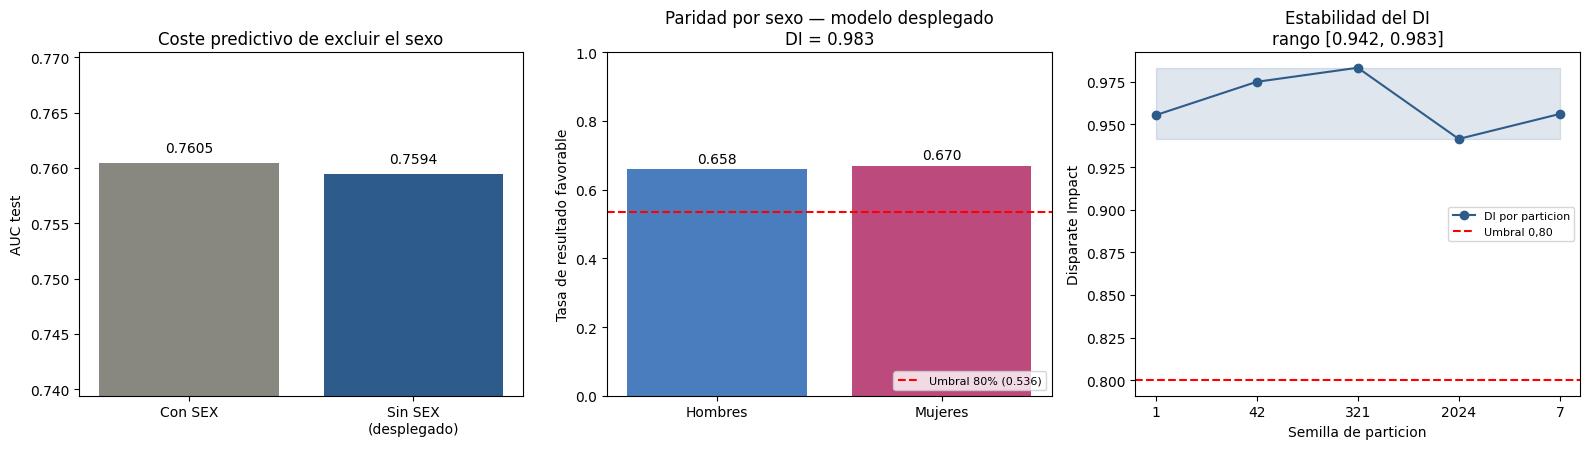

In [10]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.6))

# Coste de excluir la variable protegida
barras = ax1.bar(["Con SEX", "Sin SEX\n(desplegado)"], [auc_con, auc_sin],
                 color=["#888780", "#2E5C8A"])
ax1.set_ylim(min(auc_con, auc_sin) - 0.02, max(auc_con, auc_sin) + 0.01)
ax1.set_ylabel("AUC test")
ax1.set_title("Coste predictivo de excluir el sexo")
for b, v in zip(barras, [auc_con, auc_sin]):
    ax1.text(b.get_x() + b.get_width() / 2, v + 0.001, f"{v:.4f}", ha="center")

# Tasas de resultado favorable por grupo (modelo desplegado)
tasas = tab_sin["tasa_favorable"].values
ax2.bar(tab_sin["grupo"], tasas, color=["#4A7DBD", "#BD4A7D"])
ax2.axhline(tasas.max() * UMBRAL_DI, color="red", ls="--",
            label=f"Umbral 80% ({tasas.max() * UMBRAL_DI:.3f})")
ax2.set_ylabel("Tasa de resultado favorable")
ax2.set_title(f"Paridad por sexo — modelo desplegado\nDI = {res_sin['DI']:.3f}")
ax2.set_ylim(0, 1)
ax2.legend(loc="lower right", fontsize=8)
for i, v in enumerate(tasas):
    ax2.text(i, v + 0.02, f"{v:.3f}", ha="center")

# Dispersion del DI entre particiones
ax3.plot(sensibilidad["semilla"].astype(str), sensibilidad["DI"],
         "o-", color="#2E5C8A", label="DI por particion")
ax3.axhline(UMBRAL_DI, color="red", ls="--", label="Umbral 0,80")
ax3.fill_between(sensibilidad["semilla"].astype(str), di_min, di_max,
                 alpha=0.15, color="#2E5C8A")
ax3.set_xlabel("Semilla de particion")
ax3.set_ylabel("Disparate Impact")
ax3.set_title(f"Estabilidad del DI\nrango [{di_min:.3f}, {di_max:.3f}]")
ax3.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 9. Tabla resumen

In [11]:
resumen_memoria = pd.DataFrame([
    {"Configuracion": "Scorecard sin SEX (desplegado)",
     "AUC test": round(auc_sin, 4),
     "DI": round(res_sin["DI"], 4),
     "Cumple 80%": "Si" if res_sin["cumple_regla_80"] else "No",
     "Brecha TPR": round(res_sin["delta_TPR"], 4),
     "Brecha FPR": round(res_sin["delta_FPR"], 4)},
    {"Configuracion": "Scorecard con SEX (contrafactual)",
     "AUC test": round(auc_con, 4),
     "DI": round(res_con["DI"], 4),
     "Cumple 80%": "Si" if res_con["cumple_regla_80"] else "No",
     "Brecha TPR": round(res_con["delta_TPR"], 4),
     "Brecha FPR": round(res_con["delta_FPR"], 4)},
    {"Configuracion": f"Rango en {len(SEMILLAS)} particiones (desplegado)",
     "AUC test": f"{sensibilidad['AUC'].min():.4f}-{sensibilidad['AUC'].max():.4f}",
     "DI": f"{di_min:.4f}-{di_max:.4f}",
     "Cumple 80%": f"{n_cumplen}/{len(SEMILLAS)}",
     "Brecha TPR": f"{sensibilidad['delta_TPR'].min():.4f}-{sensibilidad['delta_TPR'].max():.4f}",
     "Brecha FPR": f"{sensibilidad['delta_FPR'].min():.4f}-{sensibilidad['delta_FPR'].max():.4f}"},
])

print(resumen_memoria.to_string(index=False))

                      Configuracion      AUC test            DI Cumple 80%    Brecha TPR    Brecha FPR
     Scorecard sin SEX (desplegado)        0.7594        0.9833         Si         0.002        0.0032
  Scorecard con SEX (contrafactual)        0.7605        0.9235         Si        0.0386        0.0382
Rango en 5 particiones (desplegado) 0.7594-0.7798 0.9415-0.9833        5/5 0.0020-0.0477 0.0013-0.0256


## 10. Conclusión

El párrafo siguiente **se genera a partir de los valores calculados arriba**, de modo
que no puede contradecir a las salidas del notebook.

In [12]:
verdicto_di = ("por encima" if res_sin["cumple_regla_80"] else "por debajo")
estabilidad = ("sin cruzar el umbral en ninguna de ellas"
               if ESTABLE else
               f"cruzando el umbral de 0,80 en {len(SEMILLAS) - n_cumplen} de {len(SEMILLAS)}")

conclusion = f"""
DECISION DE MODELADO
{'=' * 78}

El modelo final EXCLUYE la variable protegida SEX. La justificacion es triple:

1. CUMPLIMIENTO NORMATIVO. La Directiva 2004/113/CE prohibe el uso del sexo como
   factor en el acceso a bienes y servicios, incluido el credito. La exclusion no es
   una eleccion de diseno, es un requisito legal.

2. COSTE PREDICTIVO DESPRECIABLE. El IV de SEX es {iv_sex:.4f}, por debajo del umbral
   de seleccion de {IV_MINIMO}: el propio criterio estadistico del scorecard la
   descarta sin necesidad de invocar el cumplimiento. Forzando su entrada, el AUC de
   test pasa de {auc_sin:.4f} a {auc_con:.4f}, esto es {abs(auc_con - auc_sin):.4f}
   puntos, magnitud muy inferior a la anchura del intervalo de confianza del propio
   AUC. La senal de riesgo reside en el historial de pagos (PAY_1..PAY_6), no en las
   variables demograficas.

3. EQUIDAD DEL MODELO DESPLEGADO. Sobre la scorecard que consumen la API y el agente,
   el Disparate Impact es de {res_sin['DI']:.4f}, {verdicto_di} del umbral de la regla
   del 80%. El grupo con menor tasa de resultado favorable es: {res_sin['grupo_desfavorecido']}.
   Las brechas de error por grupo son de {res_sin['delta_TPR']:.4f} en tasa de acierto
   sobre morosos y {res_sin['delta_FPR']:.4f} en tasa de falsos positivos.

ROBUSTEZ DEL VEREDICTO
{'-' * 78}
Repetido el ciclo completo sobre {len(SEMILLAS)} particiones, el DI se mueve en el rango
[{di_min:.4f}, {di_max:.4f}] (media {di_media:.4f}, desviacion {di_std:.4f}),
{estabilidad}. Se informa el rango y no un unico valor puntual: apoyar una decision de
cumplimiento en una sola estimacion del DI no seria defendible ante un supervisor.

DISCRIMINACION INDIRECTA
{'-' * 78}
La correlacion maxima de una variable del modelo con el sexo es de {corr_sex.max():.4f}
({corr_sex.idxmax()}). Un modelo auxiliar que intenta reconstruir el sexo a partir
exclusivamente de las variables del scorecard alcanza un AUC de {auc_proxy_base:.4f}
(rango {min(proxy_semillas):.4f}-{max(proxy_semillas):.4f} entre particiones), lo que
indica {lectura_proxy}. Las variables de comportamiento conservan una senal residual de
sexo, insuficiente para reconstruirlo con fiabilidad pero suficiente para justificar la
monitorizacion continua de la equidad en produccion.

LIMITACIONES Y LINEAS FUTURAS
{'-' * 78}
- El DI mide paridad demografica e ignora la diferencia de riesgo real entre grupos
  (prevalencia: {tab_sin.loc[0, 'prevalencia']:.4f} frente a {tab_sin.loc[1, 'prevalencia']:.4f}).
  No puede satisfacerse simultaneamente con la igualdad de oportunidad cuando las
  prevalencias difieren, por lo que se informan ambas familias de metricas.
- La equidad se evalua sobre un unico corte temporal. En produccion debe recalcularse
  por ventanas, junto al PSI, y no certificarse de una sola vez.
- Mitigacion activa del sesgo mediante reponderacion (Fairlearn, AIF360) si la
  monitorizacion detectase deriva de las brechas por grupo.
"""

print(conclusion)


DECISION DE MODELADO

El modelo final EXCLUYE la variable protegida SEX. La justificacion es triple:

1. CUMPLIMIENTO NORMATIVO. La Directiva 2004/113/CE prohibe el uso del sexo como
   factor en el acceso a bienes y servicios, incluido el credito. La exclusion no es
   una eleccion de diseno, es un requisito legal.

2. COSTE PREDICTIVO DESPRECIABLE. El IV de SEX es 0.0088, por debajo del umbral
   de seleccion de 0.02: el propio criterio estadistico del scorecard la
   descarta sin necesidad de invocar el cumplimiento. Forzando su entrada, el AUC de
   test pasa de 0.7594 a 0.7605, esto es 0.0010
   puntos, magnitud muy inferior a la anchura del intervalo de confianza del propio
   AUC. La senal de riesgo reside en el historial de pagos (PAY_1..PAY_6), no en las
   variables demograficas.

3. EQUIDAD DEL MODELO DESPLEGADO. Sobre la scorecard que consumen la API y el agente,
   el Disparate Impact es de 0.9833, por encima del umbral de la regla
   del 80%. El grupo con menor tasa de r